# K-Means Clustering - Explained Simply

**K-Means** is a machine learning algorithm that groups similar data points together. It is an **unsupervised** algorithm: we give it data **without labels**, and it finds groups (called **clusters**) on its own.

### The shop example

Imagine you own a shop with 150 customers. You know how much each customer earns and how much they spend, but you do not know which customers belong together.

K-Means can answer:

> "Can we divide these customers into 3 natural groups?"

The groups it finds might be:

- **Budget shoppers** - lower income, lower spending
- **Regular shoppers** - medium income, medium spending
- **Premium shoppers** - higher income, higher spending

### What you will learn

1. What clustering is and how K-Means works.
2. How to explore a dataset.
3. Why scaling matters.
4. How to choose the number of clusters with the elbow method.
5. How to train, visualize, and interpret K-Means.
6. How to predict the group of a new customer.
7. How to write K-Means from scratch.

> **Note:** The dataset is synthetic (fake), but it is designed to look like real customer data. The CSV does **not** contain the true group labels - K-Means has to discover the groups by itself. That lets us practice without needing a real company's data.

## 1. What is K-Means?

### The idea in one sentence

K-Means puts every data point into the group whose **center** is closest, then moves each center to the average of its points, and repeats.

### The algorithm step by step

1. **Choose k** - the number of groups you want (for example, `k = 3`).
2. **Place k centroids** - start with k random points as the centers of the groups.
3. **Assign points** - give every point to the nearest centroid.
4. **Move centroids** - move each centroid to the average (mean) of the points assigned to it.
5. **Repeat** - repeat steps 3 and 4 until the centroids stop moving (or a maximum number of iterations is reached).

A **centroid** is just the center of a cluster. It is the average position of all points in that cluster.

### A simple analogy

Imagine 150 people standing in a field and 3 flags. Each person walks to the nearest flag. Then each flag moves to the middle of the people around it. Everyone walks to the nearest flag again. After a few rounds, the flags stop moving, and the people around each flag form a cluster.

The "nearest" is usually measured with straight-line (Euclidean) distance.

## 2. Import the tools we need

We will use:

- **NumPy** for numerical work.
- **Pandas** to load and explore the CSV file.
- **Matplotlib** to draw charts.
- **scikit-learn** for `StandardScaler` and `KMeans`.

In [4]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Make the charts a comfortable size.
plt.rcParams["figure.figsize"] = (8, 5)

ModuleNotFoundError: No module named 'matplotlib'

## 3. Load the fake customer data

The file `mall_customers.csv` contains 150 customers. Each row is one customer:

| Column | Meaning |
|---|---|
| `CustomerID` | A unique ID for each customer |
| `Annual_Income_k` | Yearly income in thousands of dollars (k$) |
| `Spending_Score` | How much the customer spends, from 1 (low) to 100 (high) |

`CustomerID` is only an identifier. We will cluster customers using income and spending score.

> **Keep the CSV in the same folder as this notebook** so `pd.read_csv("mall_customers.csv")` can find it.

In [2]:
df = pd.read_csv("mall_customers.csv")
df.head()

,CustomerID,Annual_Income_k,Spending_Score
0,1,82.1,82
1,2,43.2,59
2,3,34.8,30
3,4,56.9,63
4,5,85.7,83


### Check the size and quality of the data

Before clustering, it is always a good idea to check:

- How many rows and columns are there?
- Are any values missing?
- What do the minimum, maximum, and average values look like?

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values in each column:")
print(df.isna().sum())

print("\nSummary statistics:")
df.describe().round(1)

Rows: 150
Columns: 3

Missing values in each column:
CustomerID         0
Annual_Income_k    0
Spending_Score     0
dtype: int64

Summary statistics:


,CustomerID,Annual_Income_k,Spending_Score
count,150.0,150.0,150.0
mean,75.5,59.6,52.9
std,43.4,27.6,24.2
min,1.0,17.3,12.0
25%,38.2,34.2,29.0
50%,75.5,53.6,54.5
75%,112.8,84.8,77.0
max,150.0,127.0,96.0


## 4. Look at the data

Before using any algorithm, always look at the data. A scatter plot is perfect here because we have two features.

Each dot is one customer:

- left to right = income
- bottom to top = spending score

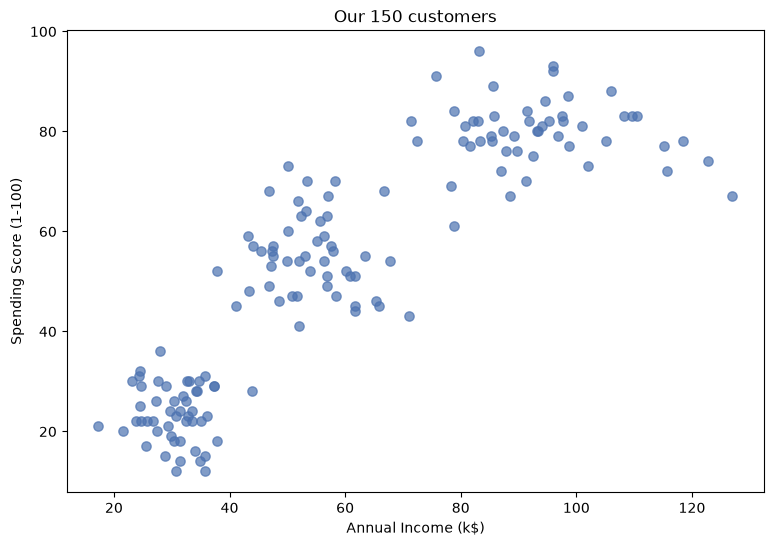

In [4]:
plt.figure(figsize=(9, 6))
plt.scatter(df["Annual_Income_k"], df["Spending_Score"], s=45, alpha=0.7, color="#4C72B0")

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Our 150 customers")
plt.show()

With two features, our eyes can already spot rough groups. But imagine a dataset with 20 features - we cannot draw a 20-dimensional scatter plot. K-Means can find groups in many dimensions automatically.

The groups we can see are not perfect. Real data is messy, and that is exactly why we let the algorithm find the patterns.

## 5. Select features and scale them

K-Means uses **distance** to decide which points are close. If one feature has much larger numbers than another, it can dominate the distance calculation.

Here, income ranges from about 17 to 127, while spending score ranges from 12 to 96. They are somewhat similar, but scaling is still good practice - especially when features have different units (dollars, years, kilometers, etc.).

`StandardScaler` transforms each feature so that:

- mean = 0
- standard deviation = 1

Now both features contribute fairly to the distance.

In [5]:
# The two features we want to cluster on.
X = df[["Annual_Income_k", "Spending_Score"]]

# Scale the features.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Before scaling (first 3 customers):")
print(X.head(3).round(1).to_string(index=False))

print("\nAfter scaling (first 3 customers):")
print(pd.DataFrame(X_scaled[:3], columns=X.columns).round(2).to_string(index=False))

Before scaling (first 3 customers):
 Annual_Income_k  Spending_Score
            82.1              82
            43.2              59
            34.8              30

After scaling (first 3 customers):
 Annual_Income_k  Spending_Score
            0.82            1.21
           -0.60            0.25
           -0.90           -0.95


### Why not use the raw values?

Scaling does not change the shape of the data; it only changes the units. After scaling, a distance of 1 in income is comparable to a distance of 1 in spending score.

> **Important:** Fit the scaler on the data used to build the model, then use the **same** scaler for any new data. This keeps the new data on the same scale as the original data.

## 6. How many clusters should we use? (Elbow method)

K-Means needs us to choose **k** before it starts. How do we pick it?

A common method is the **elbow method**:

1. Run K-Means for `k = 1, 2, 3, ...`.
2. For each k, record **inertia**. Inertia is the sum of squared distances between each point and its centroid. Lower inertia means tighter clusters.
3. Plot inertia against k.
4. Look for the "elbow" - the point where adding more clusters stops helping much.

More clusters will always reduce inertia (in the extreme, every point is its own cluster). We want the smallest k that still gives tight groups.

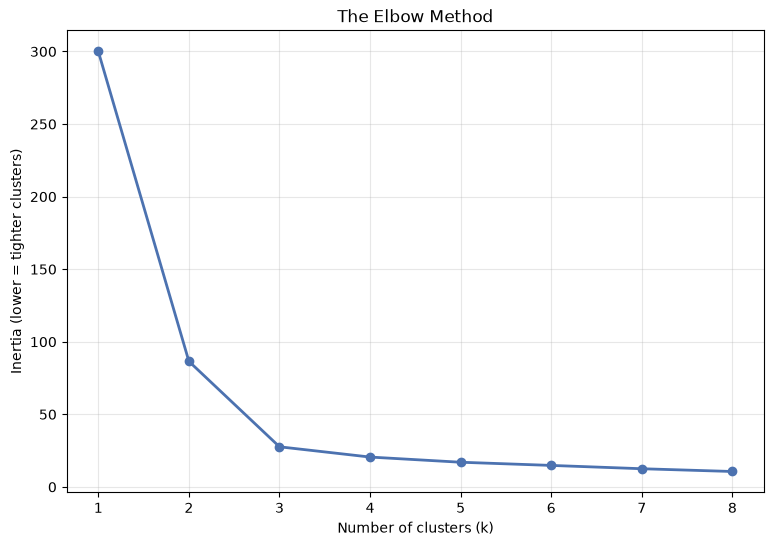

In [6]:
inertias = []
k_values = range(1, 9)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(9, 6))
plt.plot(list(k_values), inertias, marker="o", linewidth=2, color="#4C72B0")

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (lower = tighter clusters)")
plt.title("The Elbow Method")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

The curve drops steeply from k = 1 to k = 3, then the improvement becomes smaller. The "bend" around **k = 3** looks like an elbow, so 3 clusters is a reasonable choice for this dataset.

The elbow method is a guide, not a strict rule. Sometimes the data has no clear elbow, and you may need to use business knowledge or another metric.

## 7. Train K-Means with k = 3

Now we create the final model:

- `n_clusters=3` - we want 3 groups.
- `random_state=42` - makes the random starting points reproducible.
- `n_init=10` - try 10 different random starting positions and keep the best result. This reduces the chance of a bad local optimum.
- `fit(X_scaled)` - run the algorithm.

After fitting, `kmeans.labels_` tells us which cluster each customer belongs to.

In [7]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# Store the cluster number (0, 1, or 2) for each customer.
df["Cluster"] = kmeans.labels_

print("Number of customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nFinal inertia:", round(kmeans.inertia_, 2))

Number of customers in each cluster:
Cluster
0    50
1    50
2    50
Name: count, dtype: int64

Final inertia: 27.64


## 8. See the clusters and their centers

`cluster_centers_` gives the centers in **scaled** units. To understand them, we convert them back to the original units (k$ and spending score) with `scaler.inverse_transform`.

In [8]:
# Get the centroids and convert them back to the original units.
centers_scaled = kmeans.cluster_centers_
centers = scaler.inverse_transform(centers_scaled)

centers_df = pd.DataFrame(
    centers,
    columns=["Annual_Income_k", "Spending_Score"]
).round(1)

centers_df

,Annual_Income_k,Spending_Score
0,30.6,23.5
1,93.6,80.1
2,54.6,55.1


Each row is the average position of one cluster. For example, if a centroid has `Annual_Income_k = 30.6` and `Spending_Score = 23.5`, the average customer in that cluster earns about 30.6k and has a spending score of about 23.5.

Now let's draw the customers and the centroids. The black **X** marks are the centroids.

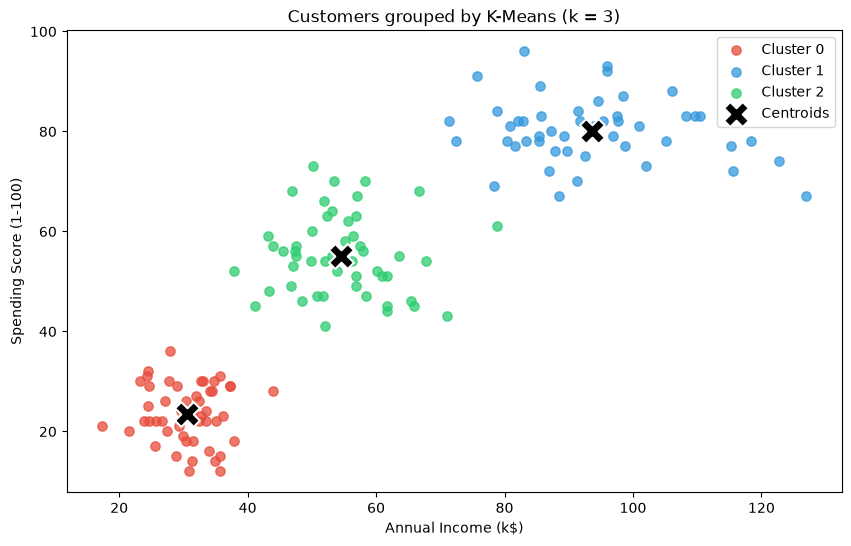

In [9]:
colors = ["#E74C3C", "#3498DB", "#2ECC71"]

plt.figure(figsize=(10, 6))

for cluster_id in sorted(df["Cluster"].unique()):
    group = df[df["Cluster"] == cluster_id]
    plt.scatter(
        group["Annual_Income_k"],
        group["Spending_Score"],
        s=45,
        alpha=0.75,
        color=colors[cluster_id],
        label=f"Cluster {cluster_id}"
    )

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=320,
    color="black",
    edgecolor="white",
    linewidth=1.5,
    label="Centroids"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customers grouped by K-Means (k = 3)")
plt.legend()
plt.show()

## 9. What do the groups mean?

A cluster number like 0, 1, or 2 is not meaningful by itself. We need to look at the average feature values in each cluster and describe the customers.

Let's make a summary table:

- `Annual_Income_k` and `Spending_Score` show the average customer in each cluster.
- `Customers` shows how many customers are in each cluster.

In [10]:
summary = (
    df.groupby("Cluster")[["Annual_Income_k", "Spending_Score"]]
      .mean()
      .round(1)
)

summary["Customers"] = df["Cluster"].value_counts().sort_index()
summary

,Annual_Income_k,Spending_Score,Customers
Cluster,,,
0,30.6,23.5,50
1,93.6,80.1,50
2,54.6,55.1,50


Now we can interpret the clusters. Your cluster numbers may be different if you change `random_state`, but the groups themselves should be similar.

- The cluster with the **lowest** average income and spending is the **budget shoppers** group.
- The cluster in the **middle** is the **regular shoppers** group.
- The cluster with the **highest** average income and spending is the **premium shoppers** group.

This is the real value of clustering: it turns numbers into understandable customer segments. A shop could use these groups for different marketing campaigns instead of treating every customer the same.

### Give the clusters friendly names

Cluster numbers are hard to remember. We can name each cluster based on its average income, from lowest to highest.

In [11]:
# Sort the cluster IDs by average income (lowest first).
order = summary["Annual_Income_k"].sort_values().index

# Map each cluster to a friendly name.
segment_names = {
    order[0]: "Budget shoppers",
    order[1]: "Regular shoppers",
    order[2]: "Premium shoppers"
}

df["Segment"] = df["Cluster"].map(segment_names)

segment_summary = (
    df.groupby("Segment")[["Annual_Income_k", "Spending_Score"]]
      .mean()
      .round(1)
)
segment_summary["Customers"] = df["Segment"].value_counts()
segment_summary

,Annual_Income_k,Spending_Score,Customers
Segment,,,
Budget shoppers,30.6,23.5,50
Premium shoppers,93.6,80.1,50
Regular shoppers,54.6,55.1,50


## 10. Predict the group of a new customer

Suppose a new customer walks in with an annual income of 60k and a spending score of 55. Which group do they belong to?

We must:

1. Put the new customer in a table with the same column names.
2. Scale the new data with the **same scaler** we used before.
3. Use `kmeans.predict()` to get the cluster.
4. Translate the cluster number into a segment name.

`predict()` does not re-train the model. It simply checks which centroid is closest to the new customer.

In [12]:
new_customer = pd.DataFrame({
    "Annual_Income_k": [60],
    "Spending_Score": [55]
})

new_customer_scaled = scaler.transform(new_customer)
new_cluster = kmeans.predict(new_customer_scaled)[0]

print("New customer:")
print(new_customer.to_string(index=False))
print("\nPredicted cluster:", new_cluster)
print("Segment:", segment_names[new_cluster])

New customer:
 Annual_Income_k  Spending_Score
              60              55

Predicted cluster: 2
Segment: Regular shoppers


## 11. K-Means from scratch (optional)

The scikit-learn version is short, but the algorithm is even simpler than it looks. Let's write our own version with NumPy to see exactly what happens inside.

We will run it on the scaled data and save the state after each iteration, so we can watch the centroids move.

In [13]:
def simple_kmeans(X, k, iterations=10, seed=42):
    """A tiny K-Means implementation for learning purposes."""
    rng = np.random.default_rng(seed)

    # Step 1: start with k random points as the first centroids.
    centers = X[rng.choice(len(X), size=k, replace=False)]

    history = []

    for step in range(iterations):
        # Step 2: assign every point to the nearest centroid.
        # X[:, None, :] and centers[None, :, :] let NumPy compare
        # every point with every centroid at once.
        distances = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2)
        labels = distances.argmin(axis=1)

        # Step 3: move each centroid to the mean of its points.
        new_centers = np.array([
            X[labels == j].mean(axis=0) if np.any(labels == j) else centers[j]
            for j in range(k)
        ])

        history.append((step + 1, labels.copy(), new_centers.copy()))
        centers = new_centers

    return labels, centers, history


labels_scratch, centers_scratch, history = simple_kmeans(X_scaled, k=3)

print("Final centroids in scaled units:")
print(np.round(centers_scratch, 2))

Final centroids in scaled units:
[[ 1.24  1.13]
 [-0.18  0.09]
 [-1.05 -1.22]]


Let's plot the first few iterations. Each black **X** is a centroid. Notice how the centroids move toward the middle of their groups, and the colors (cluster assignments) settle down.

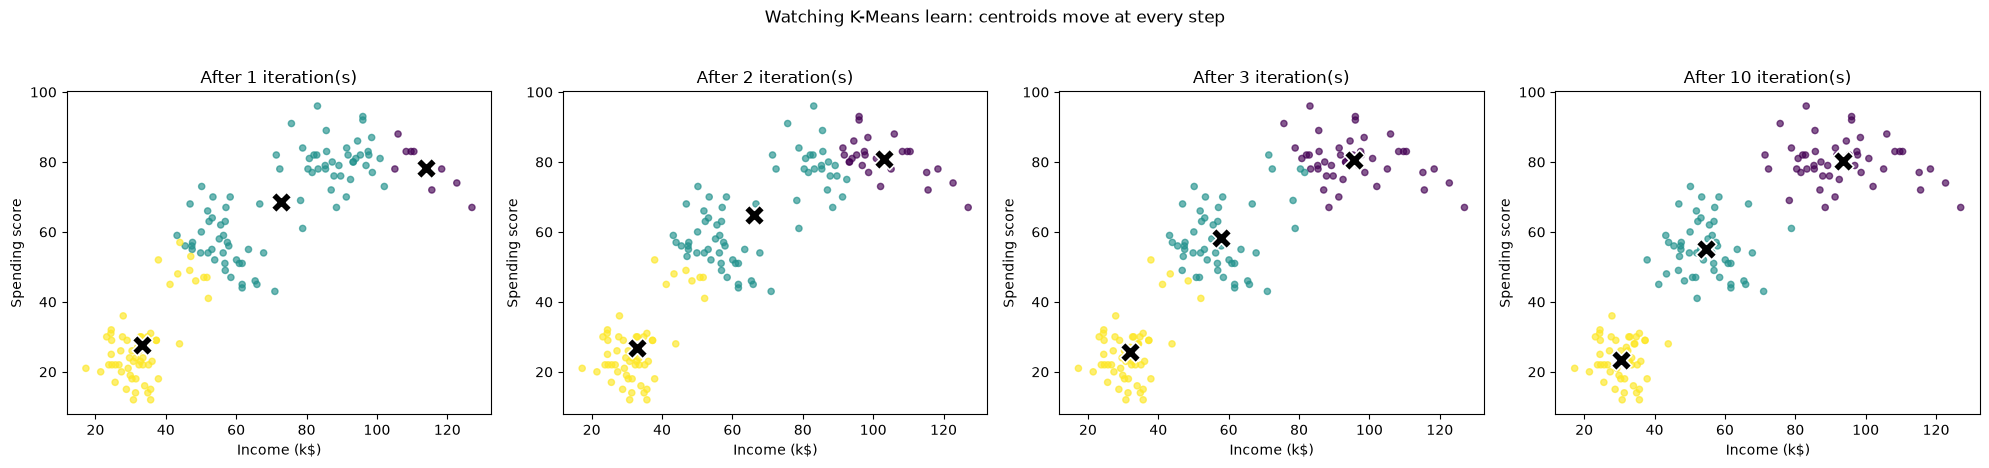

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
steps_to_show = [0, 1, 2, 9]  # iteration 1, 2, 3, and 10

for ax, index in zip(axes, steps_to_show):
    step_number, labels, centers_scaled_step = history[index]
    centers_step = scaler.inverse_transform(centers_scaled_step)

    ax.scatter(
        df["Annual_Income_k"],
        df["Spending_Score"],
        c=labels,
        cmap="viridis",
        vmin=0,
        vmax=2,
        s=20,
        alpha=0.65
    )
    ax.scatter(
        centers_step[:, 0],
        centers_step[:, 1],
        marker="X",
        s=220,
        color="black",
        edgecolor="white",
        linewidth=1.2
    )
    ax.set_title(f"After {step_number} iteration(s)")
    ax.set_xlabel("Income (k$)")
    ax.set_ylabel("Spending score")

plt.suptitle("Watching K-Means learn: centroids move at every step", y=1.03)
plt.tight_layout()
plt.show()

## 12. Recap

You made it! Here is the whole idea in one place.

### The K-Means recipe

1. Pick `k` (number of groups).
2. Start with `k` random centroids.
3. Assign each point to the nearest centroid.
4. Move each centroid to the mean of its points.
5. Repeat steps 3-4 until the centroids stop moving.

### Important lessons

- **K-Means is unsupervised.** It finds groups without being told the correct answers.
- **Scale your features.** Distance-based algorithms are sensitive to feature units.
- **Choose k carefully.** The elbow method is a simple starting point.
- **Centroids are averages.** They are useful for describing each cluster.
- **Use the same scaler for new data.** Otherwise, the distances will be wrong.
- **Cluster numbers are arbitrary.** Always interpret clusters by looking at their feature values.

### Limitations to keep in mind

- K-Means assumes clusters are roughly round and similar in size.
- It is sensitive to outliers, because outliers pull centroids toward them.
- It can get stuck in a local optimum. `n_init` in scikit-learn helps by trying several starting points.
- It cannot handle categorical features directly (you would need to encode them first).

### Try it yourself

- Change `n_clusters` to 2 or 4 and compare the plots.
- Add `Age` as a third feature (remember to scale it).
- Change `random_state` and see if the groups stay similar.
- Try the notebook on a real dataset, such as the classic Mall Customers dataset.

> **The big idea:** K-Means is just "assign to the nearest center, then move the center to the average" repeated until things stop changing. That simple loop is powerful enough to find useful groups in real data.